In [1]:
import numpy as np
import xarray as xr
import h5py
import scipy.linalg as spl
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
import tensorflow as tf
import matplotlib
import os
font = {'family' : 'serif',
        'weight' : 'normal',
        'size'   : 22}

In [2]:
rl2e_y = lambda yest, yref : spl.norm(yest - yref, 2) / spl.norm(yref, 2)

def eigenpairs(x):
    meanx = np.mean(x,axis=1)
    cov = np.cov(x)
    lam,Phi = np.linalg.eigh(cov+np.sqrt(np.finfo(float).eps) * np.eye(cov.shape[0]))
    idx = lam.argsort()[::-1]
    lamx = lam[idx]
    Phix = Phi[:,idx]
    Psix = Phix @ np.diag(np.sqrt(lamx))
    return meanx, lamx, Psix

def mesh_recon_y(arr):
    mesh = np.zeros(800)
    mesh[np.where(~np.isnan(y_ens_mesh[0,:,:,0].flatten()))] = arr
    mesh[np.where(np.isnan(y_ens_mesh[0,:,:,0].flatten()))] = np.nan
    mesh = mesh.reshape((40,20))
    return mesh

def mesh_recon_h(arr):
    recon_size = arr.shape[0]
    mesh = np.zeros(40*20*25)
    for i in range(recon_size):
        mesh[np.where(~np.isnan(h_raw[:,:,:,0].flatten()))[0]] = arr
        mesh[np.where(np.isnan(h_raw[:,:,:,0].flatten()))[0]] = np.nan
    mesh = mesh.reshape((25,40,20))
    return mesh

In [4]:
y_ens_mesh = np.log(xr.open_dataset('data/freyberg_tv_3d_k_k33_head_realizations.nc')['k'].values[:])

# h_raw = ds['head'].values[:,0,:,:,:]
# y_raw = np.log(ds['k'].values[0,:,:,:])

# mask_y = ~np.isnan(y_raw[:,:,0])
# mask_h = ~np.isnan(h_raw[:,:,:,0])
y = np.load('data/New_parameters_const.npy') # 5001 sets of conductivity+constants (2118+3)
layer1 = np.vstack([y[:706,:],y[-3,:]])
layer2 = np.vstack([y[706:706*2,:],y[-2,:]])
layer3 = np.vstack([y[706*2:706*3,:],y[-1,:]])

# y = y_raw[mask_y,:]
# h = h_raw[mask_h,:]

print(y.shape)
print(layer1.shape)
print(layer2.shape)
print(layer3.shape)

# Use the last realization as reference
# y_ref_mesh = y_raw[:,:,-1]
# h_ref_mesh = h_raw[:,:,:,-1]
# y_ref = y[:,-1]
# h_ref = h[:,-1]

train_size = 4800
test_size = 5001 - train_size


# To obtain eigen fucntions and eigenvalues using different sample sizes
meany1, lamy1, PsiY1 = eigenpairs(layer1[:,:train_size])
meany2, lamy2, PsiY2 = eigenpairs(layer2[:,:train_size])
meany3, lamy3, PsiY3 = eigenpairs(layer3[:,:train_size])
#meanh, lamh, Psih = eigenpairs(h[:,:train_size])

# Since the eigendecomposition takes a long time for head field,
# we can save it.
# with h5py.File(f'eigendecomp_wo_train_size_{train_size}.h5', 'r') as f:
#     meany = f.get('meany')[:]
#     PsiY = f.get('PsiY')[:]
#     lamy = f.get('lamy')[:]
    
#     meanh = f.get('meanh')[:]
#     Psih = f.get('Psih')[:]
#     lamh = f.get('lamh')[:]
    

# Specify the dimension that we want to use    
# NY_term = 50
# Nh_term = 150


(2121, 5001)
(707, 5001)
(707, 5001)
(707, 5001)


In [5]:
print(meany1.shape)
print(PsiY1.shape)
print(lamy1.shape)
# lamy[:1000]

(707,)
(707, 707)
(707,)


## Reduction for new data

Intersection for Top: (344, 0.9501648077522943)
Intersection for Middle: (61, 0.9503190005508242)
Intersection for Bottom: (226, 0.9500218052253923)


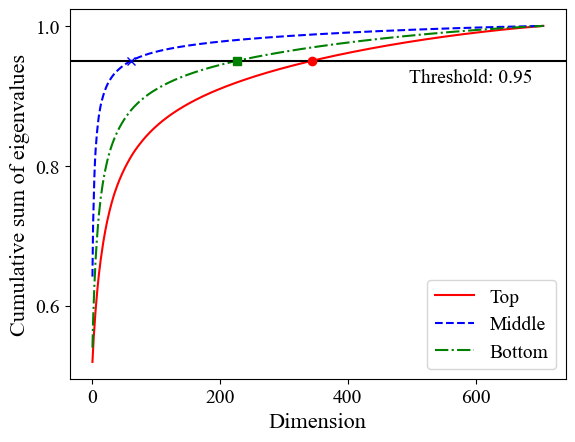

In [7]:
font = {'family' : 'Times New Roman',
        'weight' : 'normal',
        'size'   : 25}

matplotlib.rc('font', **font)

plt.plot(np.cumsum(lamy1)/np.sum(lamy1),'r-',label='Top')
plt.plot(np.cumsum(lamy2)/np.sum(lamy2),'b--',label='Middle')
plt.plot(np.cumsum(lamy3)/np.sum(lamy3),'g-.',label='Bottom')
# plt.yscale('log')
plt.axhline(y=0.95,color='black')
# Find intersections
# Function to find intersection
def find_intersection(cumsum_lamy, horizontal_value):
    idx = np.where(cumsum_lamy >= horizontal_value)[0]
    if len(idx) == 0:
        return None  # No intersection found
    idx = idx[0]
    return (idx, cumsum_lamy[idx])
intersection1 = find_intersection(np.cumsum(lamy1)/np.sum(lamy1), 0.95)
intersection2 = find_intersection(np.cumsum(lamy2)/np.sum(lamy2), 0.95)
intersection3 = find_intersection(np.cumsum(lamy3)/np.sum(lamy3), 0.95)
if intersection1:
    plt.plot(intersection1[0], intersection1[1], 'ro')
if intersection2:
    plt.plot(intersection2[0], intersection2[1], 'bx')
if intersection3:
    plt.plot(intersection3[0], intersection3[1], 'gs')

print(f'Intersection for Top: {intersection1}')
print(f'Intersection for Middle: {intersection2}')
print(f'Intersection for Bottom: {intersection3}')
plt.text(len(lamy1)*0.7, 0.92, 'Threshold: 0.95', fontsize=14, color='black')
plt.xlabel('Dimension', fontsize=16)
plt.ylabel('Cumulative sum of eigenvalues', fontsize=16)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.legend(loc='best',fontsize=14)
output_dir = "New_results"
output_path = os.path.join(output_dir, "cumulative_sum_plot.png")
# plt.savefig(output_path, dpi=600, bbox_inches='tight')
plt.show()

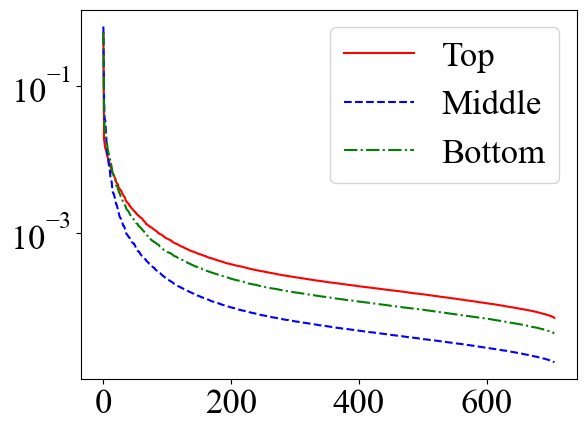

In [16]:
plt.plot((lamy1)/np.sum(lamy1),'r-',label='Top')
plt.plot((lamy2)/np.sum(lamy2),'b--',label='Middle')
plt.plot((lamy3)/np.sum(lamy3),'g-.',label='Bottom')
plt.yscale('log')
plt.legend(loc='best')

In [9]:
# Least square regression to obtain xiY and etah
# xiY is the reduced order parameter
# etah is the reduced order state variable
NY_term1 = 344
NY_term2 = 61
NY_term3 = 226
xiY1 = np.linalg.lstsq(PsiY1[:,:NY_term1],(layer1.T - meany1).T,rcond=-1)[0].T
xiY2 = np.linalg.lstsq(PsiY2[:,:NY_term2],(layer2.T - meany2).T,rcond=-1)[0].T
xiY3 = np.linalg.lstsq(PsiY3[:,:NY_term3],(layer3.T - meany3).T,rcond=-1)[0].T
# etah = np.linalg.lstsq(Psih[:,:Nh_term],(h.T - meanh).T,rcond=-1)[0].T
print(xiY1.shape)
print(xiY2.shape)
print(xiY3.shape)
# print(etah.shape)

xiY_train = xiY1[:train_size,:]
xiY_test = xiY1[train_size:,:]
# etah_train = etah[:train_size,:]
# etah_test = etah[train_size:,:]

# xiY_ref = xiY2[-1,:]
# etah_ref = etah[-1,:]
reduced_Y = np.hstack([xiY1,xiY2,xiY3])
print(reduced_Y.shape)
# np.save('New_reduced_Y_const.npy',reduced_Y)
# directory_path = 'data/newdata'
# np.save(os.path.join(directory_path, 'New_reduced_Y_const.npy'), reduced_Y)

(5001, 344)
(5001, 61)
(5001, 226)
(5001, 631)


[1.00219405 0.99760065 0.99896064 1.00062923 0.9975649  0.99855637
 1.00174256 1.00018726 0.997541   0.99760056 0.99815443 1.00164756
 1.00286133 0.99836621 0.99839899 0.99803381 0.99895568 0.9986866
 0.9948558  0.99802829 0.99822438 1.00174755 0.99982396 0.99763282
 0.9982077  0.99734452 0.99875101 1.00111361 0.99588245 1.00307889
 1.00056067 0.99767855 0.99878938 0.99917783 1.00021987 0.99879386
 0.99606467 0.9998167  0.99953381 0.99653655 1.00191143 1.00048548
 0.99672585 0.99858062 0.99806903 0.99817653 1.00541155 0.99929865
 0.99750578 0.99751497 0.99951594 0.99571794 0.99917007 0.99463399
 0.99878875 0.99786762 0.99785852 1.00067264 1.00106251 0.99759343
 0.99826622 0.99929266 0.99551108 0.99889915 0.99728271 0.99832861
 0.99695792 0.99734535 1.00414655 0.99930824 1.00124303 0.99635667
 0.9989886  0.9971876  1.00136475 0.99944394 0.99983619 0.99841541
 0.99677147 0.99784315 1.001425   0.99919101 1.0024514  1.00125973
 1.0007251  0.99685695 0.99961848 1.00005778 0.99537092 0.99906

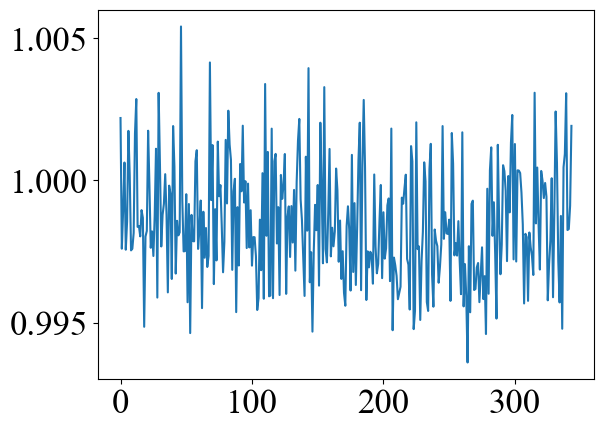

In [7]:
print(np.std(xiY1,axis=0))
plt.plot(np.std(xiY1,axis=0))

0.12763581158588705


Text(0.5, 0, 'Dimension of y')

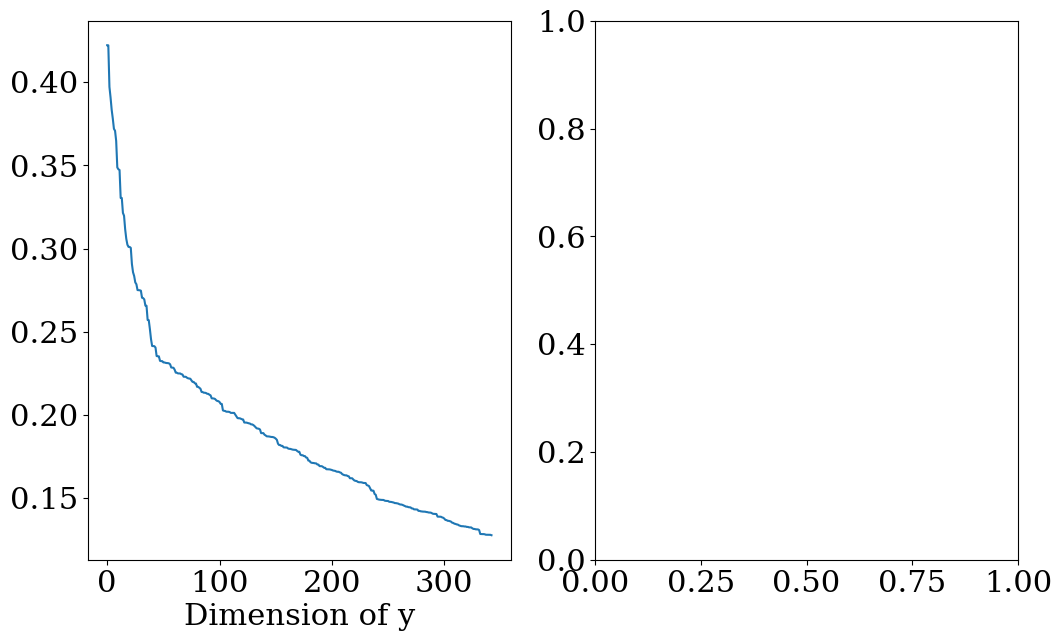

In [17]:
xiY_ref = xiY1[-1,:]
y_ref = layer1[:,-1]
err_y_recon = []
for i in range(1,344):
    err_y_recon.append(rl2e_y(meany1 + PsiY1[:,:i] @ xiY_ref[:i],y_ref))
    
print(np.min(err_y_recon))

fig, ax  = plt.subplots(1,2,figsize=(12,7))
ax[0].plot(err_y_recon)
ax[0].set_xlabel('Dimension of y')


0.07449140327677618


Text(0.5, 0, 'Dimension of y')

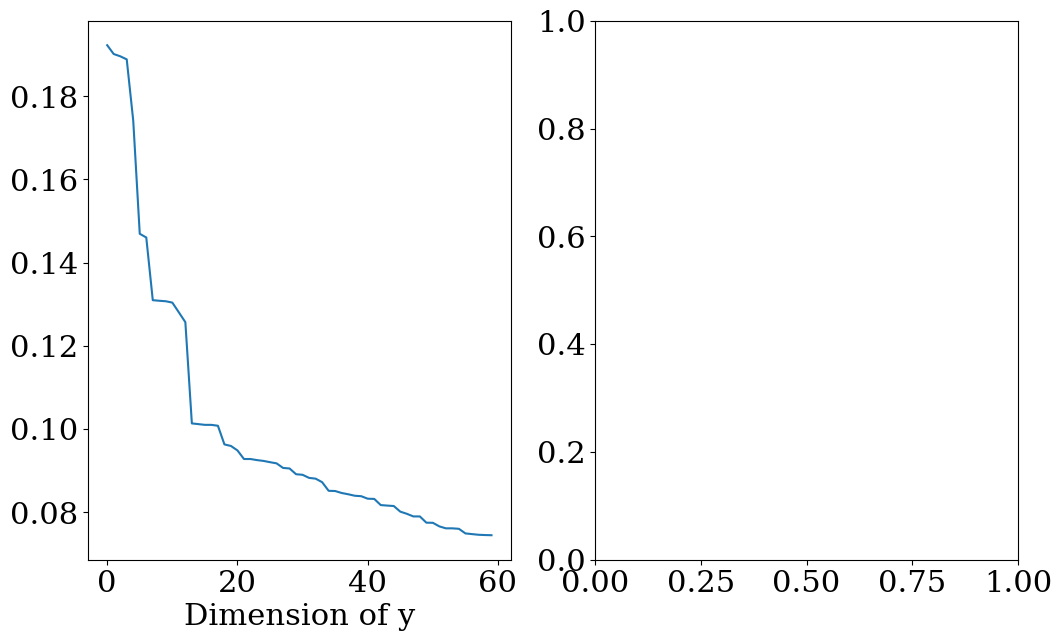

In [18]:
xiY_ref = xiY2[-1,:]
y_ref = layer2[:,-1]
err_y_recon = []
for i in range(1,61):
    err_y_recon.append(rl2e_y(meany2 + PsiY2[:,:i] @ xiY_ref[:i],y_ref))
    
print(np.min(err_y_recon))

fig, ax  = plt.subplots(1,2,figsize=(12,7))
ax[0].plot(err_y_recon)
ax[0].set_xlabel('Dimension of y')

0.03057434639307296


Text(0.5, 0, 'Dimension of y')

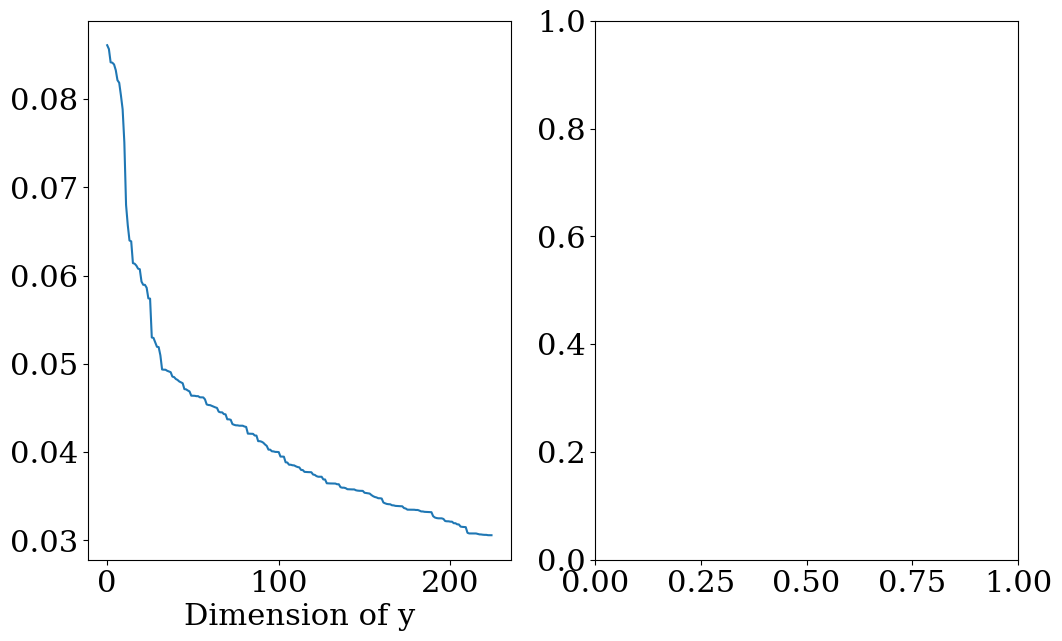

In [19]:
xiY_ref = xiY3[-1,:]
y_ref = layer3[:,-1]
err_y_recon = []
for i in range(1,226):
    err_y_recon.append(rl2e_y(meany3 + PsiY3[:,:i] @ xiY_ref[:i],y_ref))
    
print(np.min(err_y_recon))

fig, ax  = plt.subplots(1,2,figsize=(12,7))
ax[0].plot(err_y_recon)
ax[0].set_xlabel('Dimension of y')

In [7]:
etah.shape
# np.save('reduced_parameter50D.npy',xiY)
# np.save('reduced_data.npy',etah)

## Load posterior samples for reduced dimension:631

In [24]:
samples_mean=np.load('reduced_const_postmean.npy')
samples_std=np.load('reduced_const_poststd.npy')
print(samples_mean.shape)
layer1_mean = samples_mean[:,:344]
layer2_mean = samples_mean[:,344:(344+61)]
layer3_mean = samples_mean[:,-226:]
post_samples = np.load('reduced_const_postsamples.npy')
print(post_samples.shape)


(101, 631)
(101, 2000, 631)


## 12 layers

In [8]:
samples_mean=np.load('New_results/New_reduced_const_postmean.npy')
samples_std=np.load('New_results/New_reduced_const_poststd.npy')
# samples_mean=np.load('New_results/NosiyNew_reduced_const_postmean.npy')
# samples_std=np.load('New_results/NosiyNew_reduced_const_poststd.npy')
print(samples_mean.shape)
layer1_mean = samples_mean[:,:344]
layer2_mean = samples_mean[:,344:(344+61)]
layer3_mean = samples_mean[:,-226:]
post_samples = np.load('New_results/New_reduced_const_postsamples.npy')
# post_samples = np.load('New_results/NosiyNew_reduced_const_postsamples.npy')
print(post_samples.shape)


(101, 631)
(101, 2000, 631)


## Training size=1696

In [51]:
samples_mean=np.load('New_results/New_reduced_const_postmean1969.npy')
samples_std=np.load('New_results/New_reduced_const_poststd1696.npy')
# samples_mean=np.load('New_results/NosiyNew_reduced_const_postmean.npy')
# samples_std=np.load('New_results/NosiyNew_reduced_const_poststd.npy')
print(samples_mean.shape)
layer1_mean = samples_mean[:,:344]
layer2_mean = samples_mean[:,344:(344+61)]
layer3_mean = samples_mean[:,-226:]
post_samples = np.load('New_results/New_reduced_const_postsamples1696.npy')
# post_samples = np.load('New_results/NosiyNew_reduced_const_postsamples.npy')
print(post_samples.shape)


(101, 631)
(101, 2000, 631)


## 61 parameters 

In [26]:
samples_mean=np.load('reduced_const_postmean61.npy')
samples_std=np.load('reduced_const_poststd61.npy')
print(samples_mean.shape)
mean_ext = np.zeros([101,631])
mean_ext[:,0] = samples_mean[:,0]
mean_ext[:,344:354] = samples_mean[:,1:11]
mean_ext[:,405:455] = samples_mean[:,11:61]
print(mean_ext.shape)

layer1_mean = mean_ext[:,:344]
layer2_mean = mean_ext[:,344:(344+61)]
layer3_mean = mean_ext[:,-226:]

post_samples = np.load('reduced_const_postsamples61.npy')
print(post_samples.shape)


(101, 61)
(101, 631)
(101, 2000, 61)


In [32]:
samples_ext = np.zeros([101,2000,631])
samples_ext[:,:,0] = post_samples[:,:,0]
samples_ext[:,:,344:354] = post_samples[:,:,1:11]
samples_ext[:,:,405:455] = post_samples[:,:,11:61]
print(samples_ext.shape)


(101, 2000, 631)


## Reconstruction from low-dimension to original space: -->707

In [9]:
# post_samples = post_samples #samples_ext
Ntest=-1
NY_term1=344
# y_recon1 = meany1 + PsiY1[:,:NY_term1] @ layer1_mean[Ntest,:NY_term1]
y_recon1 = []
for i in range(2000):
    y1 = meany1 + PsiY1[:,:NY_term1] @ post_samples[Ntest,i,:NY_term1]
    y_recon1.append(y1)
y_recon1_t = np.array(y_recon1)
y_recon1_mean = np.mean(y_recon1_t,axis=0)
y_recon1_std = np.std(y_recon1_t,axis=0)
print(y_recon1_t.shape)

NY_term2=61
# y_recon2 = meany2 + PsiY2[:,:NY_term2] @ layer2_mean[Ntest,:NY_term2]
y_recon2 = []
for i in range(2000):
    y2 = meany2 + PsiY2[:,:NY_term2] @ post_samples[Ntest,i,344:405]
    y_recon2.append(y2)
y_recon2_t = np.array(y_recon2)
y_recon2_mean = np.mean(y_recon2_t,axis=0)
y_recon2_std = np.std(y_recon2_t,axis=0)
print(y_recon2_t.shape)

NY_term3=226
# y_recon3 = meany3 + PsiY3[:,:NY_term3] @ layer3_mean[Ntest,:NY_term3]
y_recon3 = []
for i in range(2000):
    y3 = meany3 + PsiY3[:,:NY_term3] @ post_samples[Ntest,i,-226:]
    y_recon3.append(y3)
y_recon3_t = np.array(y_recon3)
y_recon3_mean = np.mean(y_recon3_t,axis=0)
y_recon3_std = np.std(y_recon3_t,axis=0)
print(y_recon3_t.shape)

# print(rl2e_y(np.mean(recon,axis=0),y_ref))
y_reconAll_mean = np.hstack([y_recon1_mean[:706],y_recon2_mean[:706],y_recon3_mean[:706]])
y_reconAll_std = np.hstack([y_recon1_std[:706],y_recon2_std[:706],y_recon3_std[:706]])
print(y_reconAll_mean.shape)
print(y_reconAll_std.shape)
# y_reconAll_std



(2000, 707)
(2000, 707)
(2000, 707)
(2118,)
(2118,)


In [27]:
K_samples = np.hstack([y_recon1_t[:,:707],y_recon2_t[:,:707],y_recon3_t[:,:707]])
print(K_samples.shape)
# np.save('K_samples_for_heads.npy',K_samples)
mesh_recon_y(y_recon1_t[0,:706]).shape

(2000, 2121)


(40, 20)

In [18]:
layer1_prior_m,layer1_prior_s = np.mean(layer1,axis=1)[:706],np.std(layer1,axis=1)[:706]
layer2_prior_m,layer2_prior_s = np.mean(layer2,axis=1)[:706],np.std(layer2,axis=1)[:706]
layer3_prior_m,layer3_prior_s = np.mean(layer3,axis=1)[:706],np.std(layer3,axis=1)[:706]

y_reconAll_mean[1:706],y_reconAll_std[1:706]=layer1_prior_m[1:706],layer1_prior_s[1:706]
y_reconAll_mean[716:1412],y_reconAll_std[716:1412]=layer2_prior_m[10:706],layer2_prior_s[10:706]
y_reconAll_mean[1462:2118],y_reconAll_std[1462:2118]=layer3_prior_m[50:706],layer3_prior_s[50:706]

[-2.19902667 -2.30559374 -2.46548622]
[-2.6451247  -2.31772807 -2.41653192]


/var/folders/x4/zwvf8_gn4kv9m8th8jw6cfsw0000gn/T/ipykernel_66465/2852204753.py:27: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(theta_samples_p, kde=True, kde_kws={ "lw": 4},hist=False, ax=axarr[j],
/var/folders/x4/zwvf8_gn4kv9m8th8jw6cfsw0000gn/T/ipykernel_66465/2852204753.py:27: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwasko

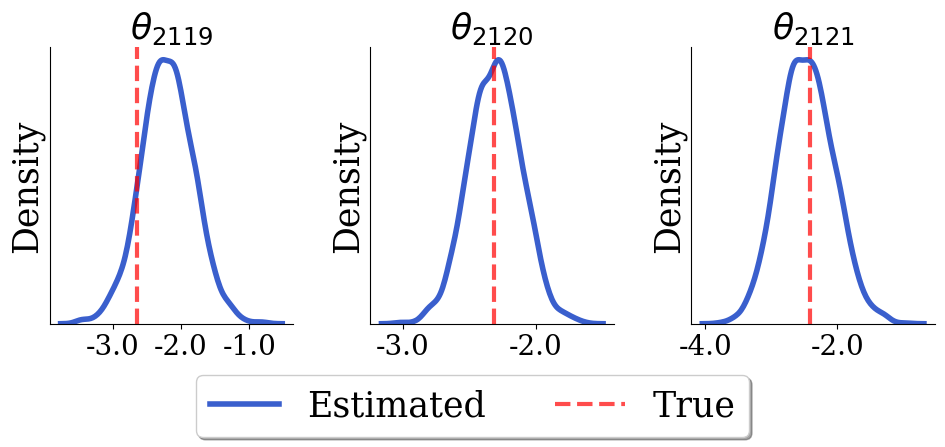

In [11]:
import seaborn as sns
from matplotlib.ticker import FormatStrFormatter
font = {'family' : 'serif',
        'weight' : 'normal',
        }

matplotlib.rc('font', **font)

theta_dim=2121
params_names = [r'$\theta_{}$'.format({i+1}) for i in range(theta_dim)]

consts_samples = np.vstack([y_recon1_t[:,-1],y_recon2_t[:,-1],y_recon3_t[:,-1]])
print(np.mean(consts_samples,axis=1)) # 3x2000


f, axarr = plt.subplots(1, 3, figsize=(10, 4))
axarr = np.atleast_2d(axarr)
axarr = axarr.flat

sample_inverse_p=consts_samples
theta_samples_means=y[:,(4800+100):(4800+201)][-3:,60]
print(theta_samples_means)

# For each row 
for j in range(3):
    theta_samples_p = consts_samples[j,:]
    sns.distplot(theta_samples_p, kde=True, kde_kws={ "lw": 4},hist=False, ax=axarr[j], 
                        label='Estimated', color='#3A5FCD')
    # axarr[ j].axvline(theta_samples_means_bf[0, j], color='r', label='cINN')
    axarr[ j].axvline(theta_samples_means[j], color='r',linestyle='--',lw=3, label='True',alpha=0.7)
    # axarr[ j].axvline(theta_samples_means_mc[j],color='r', label='CNN', linestyle='dashed',linewidth=3)
    axarr[ j].spines['right'].set_visible(False)
    axarr[ j].spines['top'].set_visible(False)
    axarr[ j].xaxis.set_major_formatter(FormatStrFormatter('%.1f'))
    axarr[ j].get_yaxis().set_ticks([])
    axarr[j].xaxis.set_tick_params(labelsize=20)
    axarr[j].yaxis.set_tick_params(labelsize=20)
    axarr[j].set_ylabel('Density', fontsize=25)
    
    if j == 0:
        f.legend(loc='lower center', bbox_to_anchor=(0.5, -0.25), shadow=True, ncol=4, fontsize=25, borderaxespad=1) 
      
    axarr[j].set_title(params_names[-3:][j],fontsize=25)
    axarr[j].spines['right'].set_visible(False)
    axarr[j].spines['top'].set_visible(False)
                        
f.tight_layout()
f.subplots_adjust(bottom=0.12)
plt.show()

In [12]:
y_reconAll_std

array([0.62468713, 0.61589978, 0.61616042, ..., 0.35729691, 0.37330383,
       0.3754848 ])

In [55]:
# index = [706, 707*2-1, 707*3-1]
# y_const_mean = y_reconAll_mean[index]
# y_const_std = y_reconAll_std[index]
# print(y_const_mean)
# print(y_const_std)

# indices_to_remove = np.array([706, 707*2-1, 707*3-1])
# mask = np.ones(y_reconAll_mean.shape[0], dtype=bool)
# mask[indices_to_remove] = False
# y_reconAll_mean_temp = y_reconAll_mean[mask]
# y_reconAll_std_temp = y_reconAll_std[mask]
# print(y_reconAll_mean_temp.shape)
# print(y_reconAll_std_temp.shape)

In [54]:
# Ntest = -1
# y_ref = y[:,(4800+100):(4800+201)][:2118,Ntest]

# overall_error = rl2e_y(y_reconAll_mean_temp,y_ref)
# print('The overall L2 error:',overall_error)
# top_error = rl2e_y(y_reconAll_mean_temp[:706],y_ref[:706])
# mid_error = rl2e_y(y_reconAll_mean_temp[706:706*2],y_ref[706:706*2])
# bot_error = rl2e_y(y_reconAll_mean_temp[-706:],y_ref[-706:])
# print('The top L2 error:',top_error)
# print('The middle L2 error:',mid_error)
# print('The bottom L2 error:',bot_error)

## Results using 1696 training data

In [54]:
Ntest = -1
y_ref = y[:,(4800+100):(4800+201)][:2118,Ntest]

overall_error = rl2e_y(y_reconAll_mean,y_ref)
print('The overall L2 error:',overall_error)
top_error = rl2e_y(y_reconAll_mean[:706],y_ref[:706])
mid_error = rl2e_y(y_reconAll_mean[706:706*2],y_ref[706:706*2])
bot_error = rl2e_y(y_reconAll_mean[-706:],y_ref[-706:])
print('The top L2 error:',top_error)
print('The middle L2 error:',mid_error)
print('The bottom L2 error:',bot_error)

The overall L2 error: 0.2070211888335632
The top L2 error: 0.7312921556105494
The middle L2 error: 0.2785676052045535
The bottom L2 error: 0.08872311873636578


In [55]:
def rmse_y(y_pred, y_true):
    if len(y_pred) != len(y_true):
        raise ValueError("y_pred and y_true must have the same length.")
    return np.sqrt(np.mean((np.array(y_pred) - np.array(y_true)) ** 2))
overall_error = rmse_y(y_reconAll_mean, y_ref)
print('The overall RMSE:', overall_error)

# Compute the RMSE for the top, middle, and bottom segments
top_error = rmse_y(y_reconAll_mean[:706], y_ref[:706])
mid_error = rmse_y(y_reconAll_mean[706:706*2], y_ref[706:706*2])
bot_error = rmse_y(y_reconAll_mean[-706:], y_ref[-706:])

# Print the segment-specific RMSE values
print('The top RMSE:', top_error)
print('The middle RMSE:', mid_error)
print('The bottom RMSE:', bot_error)

The overall RMSE: 0.44880239605086303
The top RMSE: 0.6186379884114191
The middle RMSE: 0.35961332203439755
The bottom RMSE: 0.30370391833600796


In [56]:
def lpp_ens(pred_mean,pred_std,alpha): # ens is predicted, alpha is true
    mu = pred_mean
    sigma = pred_std
    return -np.sum((mu-alpha)**2/(2*(sigma)**2) + np.log(2*np.pi*sigma**2)/2)

LPP=lpp_ens(y_reconAll_mean,y_reconAll_std,y_ref)
print('The overall LPP:',LPP)

LPP1=lpp_ens(y_reconAll_mean[:706],y_reconAll_std[:706],y_ref[:706])
print('The top LPP:',LPP1)

LPP2=lpp_ens(y_reconAll_mean[706:1412],y_reconAll_std[706:1412],y_ref[706:1412])
print('The middle LPP:',LPP2)

LPP3=lpp_ens(y_reconAll_mean[-706:],y_reconAll_std[-706:],y_ref[-706:])
print('The bottom LPP:',LPP3)

The overall LPP: -1093.2018003313096
The top LPP: -667.0172742889051
The middle LPP: -276.4099878693407
The bottom LPP: -149.77453817306377


## New results from new data

In [13]:
Ntest = -1
y_ref = y[:,(4800+100):(4800+201)][:2118,Ntest]

overall_error = rl2e_y(y_reconAll_mean,y_ref)
print('The overall L2 error:',overall_error)
top_error = rl2e_y(y_reconAll_mean[:706],y_ref[:706])
mid_error = rl2e_y(y_reconAll_mean[706:706*2],y_ref[706:706*2])
bot_error = rl2e_y(y_reconAll_mean[-706:],y_ref[-706:])
print('The top L2 error:',top_error)
print('The middle L2 error:',mid_error)
print('The bottom L2 error:',bot_error)

The overall L2 error: 0.2191577194452109
The top L2 error: 0.8586725556946561
The middle L2 error: 0.23490518576744346
The bottom L2 error: 0.07010545308701127


In [14]:
def rmse_y(y_pred, y_true):
    if len(y_pred) != len(y_true):
        raise ValueError("y_pred and y_true must have the same length.")
    return np.sqrt(np.mean((np.array(y_pred) - np.array(y_true)) ** 2))
overall_error = rmse_y(y_reconAll_mean, y_ref)
print('The overall RMSE:', overall_error)

# Compute the RMSE for the top, middle, and bottom segments
top_error = rmse_y(y_reconAll_mean[:706], y_ref[:706])
mid_error = rmse_y(y_reconAll_mean[706:706*2], y_ref[706:706*2])
bot_error = rmse_y(y_reconAll_mean[-706:], y_ref[-706:])

# Print the segment-specific RMSE values
print('The top RMSE:', top_error)
print('The middle RMSE:', mid_error)
print('The bottom RMSE:', bot_error)

The overall RMSE: 0.47511324881401296
The top RMSE: 0.7263956798709729
The middle RMSE: 0.3032478746224176
The bottom RMSE: 0.23997466615789334


In [16]:
def lpp_ens(pred_mean,pred_std,alpha): # ens is predicted, alpha is true
    mu = pred_mean
    sigma = pred_std
    return -np.sum((mu-alpha)**2/(2*(sigma)**2) + np.log(2*np.pi*sigma**2)/2)

LPP=lpp_ens(y_reconAll_mean,y_reconAll_std,y_ref)
print('The overall LPP:',LPP)

LPP1=lpp_ens(y_reconAll_mean[:706],y_reconAll_std[:706],y_ref[:706])
print('The top LPP:',LPP1)

LPP2=lpp_ens(y_reconAll_mean[706:1412],y_reconAll_std[706:1412],y_ref[706:1412])
print('The middle LPP:',LPP2)

LPP3=lpp_ens(y_reconAll_mean[-706:],y_reconAll_std[-706:],y_ref[-706:])
print('The bottom LPP:',LPP3)

The overall LPP: -998.3585901003291
The top LPP: -797.2044106570345
The middle LPP: -181.09163100445932
The bottom LPP: -20.062548438835258


In [25]:
import pandas as pd

# Data from Table 1
table1 = {
    "Overall": [0.286827129, -1685.68901],
    "Top": [1.1808337724, -1201.61857],
    "Middle": [0.2422109373, -359.70076],
    "Bottom": [0.074295603, -120.86475]
}
table1_df = pd.DataFrame(table1, index=["Relative L2 error", "LPP"])

# Data from Table 2
table2 = {
    "Overall": [0.21915771, -998.35859010],
    "Top": [0.8586725516, -797.20441065],
    "Middle": [0.214905185, -181.09163100],
    "Bottom": [0.07010545353, -20.06254843]
}
table2_df = pd.DataFrame(table2, index=["Relative L2 error", "LPP"])

# Calculate the improvement percentage ((table1 - table2) / table1) * 100
improvement = (table1_df - table2_df) / table1_df * 100


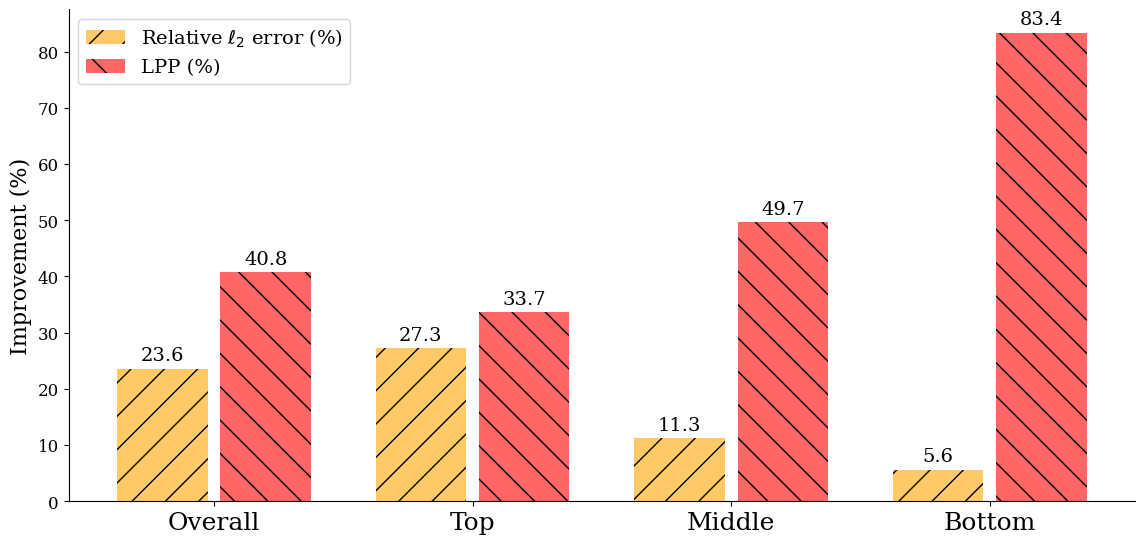

In [46]:
# Combine data for Relative L2 Error and LPP improvements
categories = ["Overall", "Top", "Middle", "Bottom"]
relative_l2_error = improvement.loc["Relative L2 error"]
lpp = improvement.loc["LPP"]

# Plotting combined bar chart with hatches
spacing = 0.0  # Space between bar groups
x = np.arange(len(categories)) * (1 + spacing)  # Add spacing between bar groups
offset=0.05
width = 0.35  # Bar width

fig, ax = plt.subplots(figsize=(12, 6))

# Bar plots with hatches

bars1 = ax.bar(x - width / 2 - offset / 2, relative_l2_error, width, label="Relative $\\ell_2$ error (%)", hatch='/', color='orange',alpha=0.6)
bars2 = ax.bar(x + width / 2 + offset / 2, lpp, width, label="LPP (%)", hatch='\\', color='red',alpha=0.6)

# Add labels, title, and legend
# ax.set_xlabel("Categories", fontsize=14)
ax.set_ylabel("Improvement (%)", fontsize=16)
ax.tick_params(axis='y', labelsize=12)
# ax.set_title("Percentage Improvement of Table 2 Over Table 1", fontsize=16)
ax.set_xticks(x)
ax.set_xticklabels(categories, fontsize=18)
ax.legend(fontsize=14)

for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f"{height:.1f}",
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3),  # Offset text above bar
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=14)
# Remove upper and right spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
output_dir = "New_results"
output_path = os.path.join(output_dir, "improvement.png")
plt.savefig(output_path, dpi=600, bbox_inches='tight')
plt.show()


## Old results from old data

In [69]:
Ntest = -1
y_ref = y[:,(4800+100):(4800+201)][:2118,Ntest]

overall_error = rl2e_y(y_reconAll_mean,y_ref)
print('The overall L2 error:',overall_error)
top_error = rl2e_y(y_reconAll_mean[:706],y_ref[:706])
mid_error = rl2e_y(y_reconAll_mean[706:706*2],y_ref[706:706*2])
bot_error = rl2e_y(y_reconAll_mean[-706:],y_ref[-706:])
print('The top L2 error:',top_error)
print('The middle L2 error:',mid_error)
print('The bottom L2 error:',bot_error)

The overall L2 error: 0.23162268533355893
The top L2 error: 0.9455225161133315
The middle L2 error: 0.1795207471577769
The bottom L2 error: 0.07328353765463382


In [70]:
def lpp_ens(pred_mean,pred_std,alpha): # ens is predicted, alpha is true
    mu = pred_mean
    sigma = pred_std
    return -np.sum((mu-alpha)**2/(2*(sigma)**2) + np.log(2*np.pi*sigma**2)/2)

LPP=lpp_ens(y_reconAll_mean,y_reconAll_std,y_ref)
print('The overall LPP:',LPP)

LPP1=lpp_ens(y_reconAll_mean[:706],y_reconAll_std[:706],y_ref[:706])
print('The top LPP:',LPP1)

LPP2=lpp_ens(y_reconAll_mean[706:1412],y_reconAll_std[706:1412],y_ref[706:1412])
print('The middle LPP:',LPP2)

LPP3=lpp_ens(y_reconAll_mean[-706:],y_reconAll_std[-706:],y_ref[-706:])
print('The bottom LPP:',LPP3)

The overall LPP: -1082.9353673804362
The top LPP: -960.9778926965164
The middle LPP: -82.43734931905831
The bottom LPP: -39.52012536486147


## 1697 taining size

{'Top Layer Coverage Rate': 0.9801699716713881, 'Middle Layer Coverage Rate': 0.9674220963172805, 'Bottom Layer Coverage Rate': 0.9575070821529745}


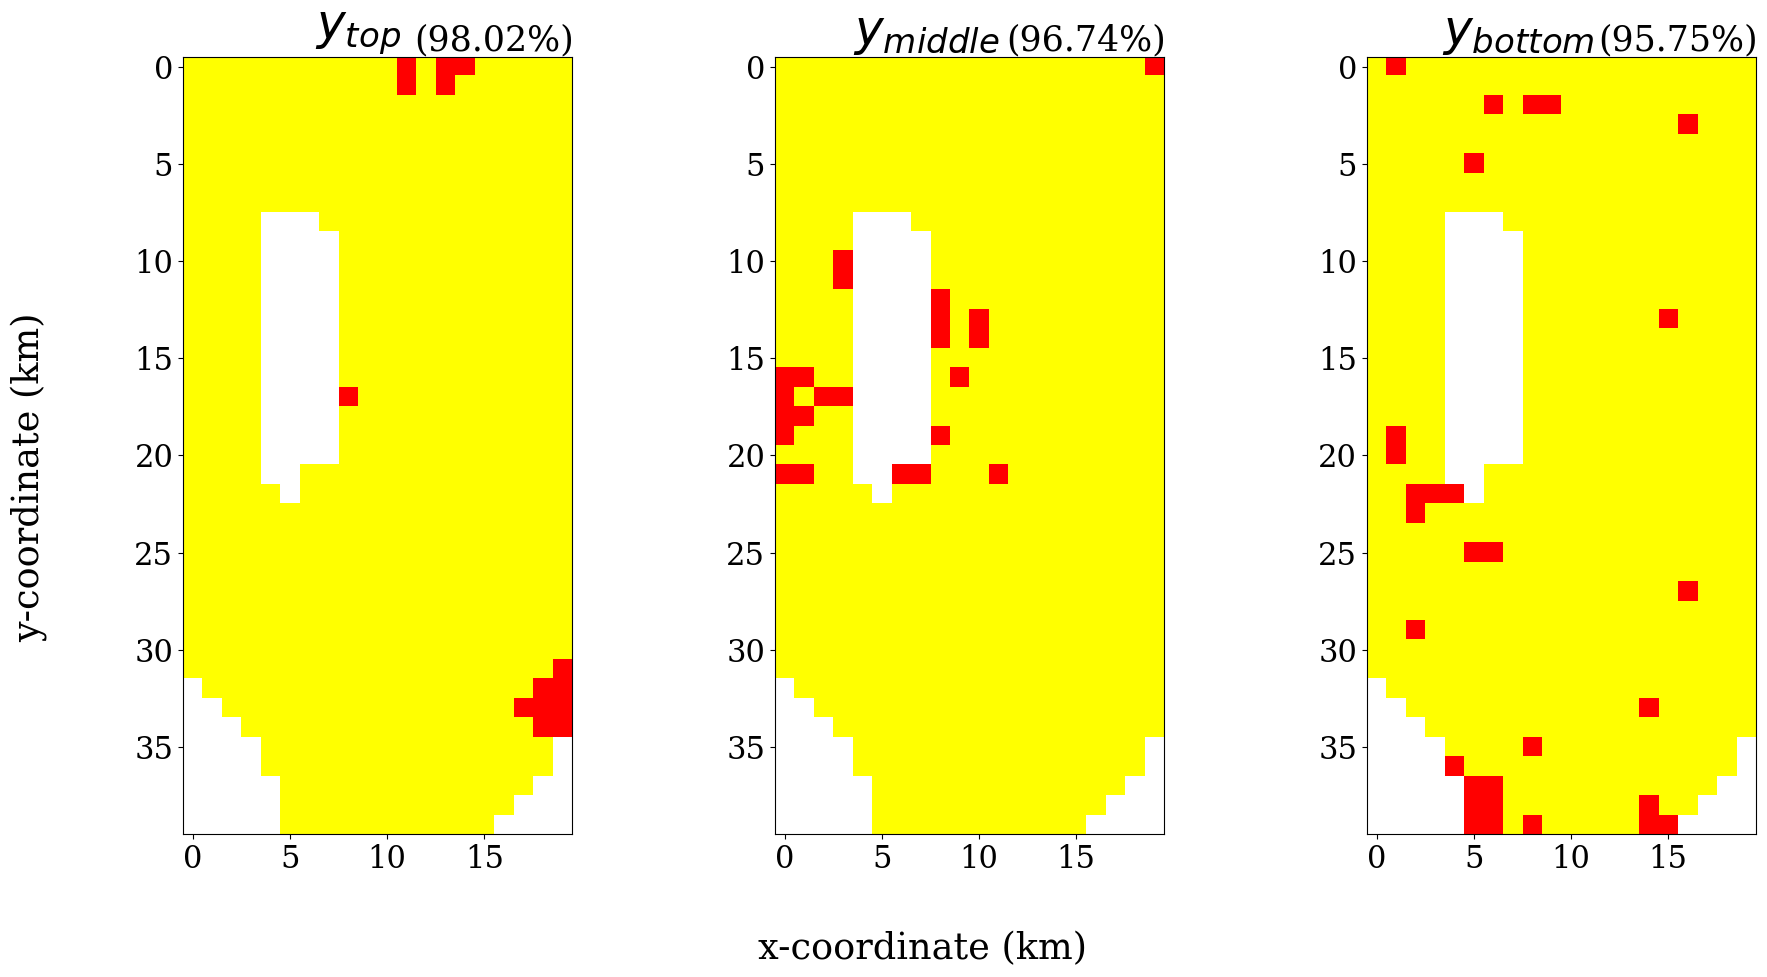

In [41]:
# compute coverage
No=1
CI=np.zeros([No,2118])
for i in range(No):
    for j in range(2118):
        if ((y_ref[j]>=y_reconAll_mean[j]-2*y_reconAll_std[j]) and (y_ref[j]<=y_reconAll_mean[j]+2*y_reconAll_std[j])):
            CI[i,j]=0.6
        else:
            CI[i,j]=0 # black
num_points_per_layer = 706

# Compute the coverage rates
coverage_top = np.sum(CI[0, :num_points_per_layer] == 0.6) / num_points_per_layer
coverage_middle = np.sum(CI[0, num_points_per_layer:num_points_per_layer*2] == 0.6) / num_points_per_layer
coverage_bottom = np.sum(CI[0, -num_points_per_layer:] == 0.6) / num_points_per_layer
coverage_rates = {
    "Top Layer Coverage Rate": coverage_top,
    "Middle Layer Coverage Rate": coverage_middle,
    "Bottom Layer Coverage Rate": coverage_bottom,
}
print(coverage_rates)           
# plot CI95% and 99%

# CI[0,900]=0
f, (ax7, ax8,ax9) = plt.subplots(1, 3,figsize=(19,10))
conI95_1=ax7.imshow(mesh_recon_y(CI[0,:706]),cmap='autumn')
divider = make_axes_locatable(ax7)
# cax = divider.append_axes("right", size="5%", pad=0.05)
# f.colorbar(conI95, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax7.text(0.45, 1.0, "$y_{top}$", fontsize=35, ha='center', va='bottom', transform=ax7.transAxes)
ax7.text(0.8, 1.0, f"({coverage_top:.2%})", fontsize=25, ha='center', va='bottom', transform=ax7.transAxes)


conI95_2=ax8.imshow(mesh_recon_y(CI[0,706:706*2]),cmap='autumn')
divider = make_axes_locatable(ax8)
# cax = divider.append_axes("right", size="5%", pad=0.05)
# f.colorbar(conI99, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
# ax8.set_title('$y_{middle}$',fontsize=35)
ax8.text(0.39, 1.0, "$y_{middle}$", fontsize=35, ha='center', va='bottom', transform=ax8.transAxes)
ax8.text(0.8, 1.0, f"({coverage_middle:.2%})", fontsize=25, ha='center', va='bottom', transform=ax8.transAxes)

conI95_3=ax9.imshow(mesh_recon_y(CI[0,-706:]),cmap='autumn')
divider = make_axes_locatable(ax9)
# cax = divider.append_axes("right", size="5%", pad=0.05)
# f.colorbar(conI99, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
# ax9.set_title('$y_{bottom}$',fontsize=35)
ax9.text(0.39, 1.0, "$y_{bottom}$", fontsize=35, ha='center', va='bottom', transform=ax9.transAxes)
ax9.text(0.8, 1.0, f"({coverage_bottom:.2%})", fontsize=25, ha='center', va='bottom', transform=ax9.transAxes)

f.supxlabel('x-coordinate (km)')
f.supylabel('y-coordinate (km)')

f.tight_layout()
# output_dir = "New_results"
# output_path = os.path.join(output_dir, "coverage.png")
# plt.savefig(output_path, dpi=600, bbox_inches='tight')
plt.show()

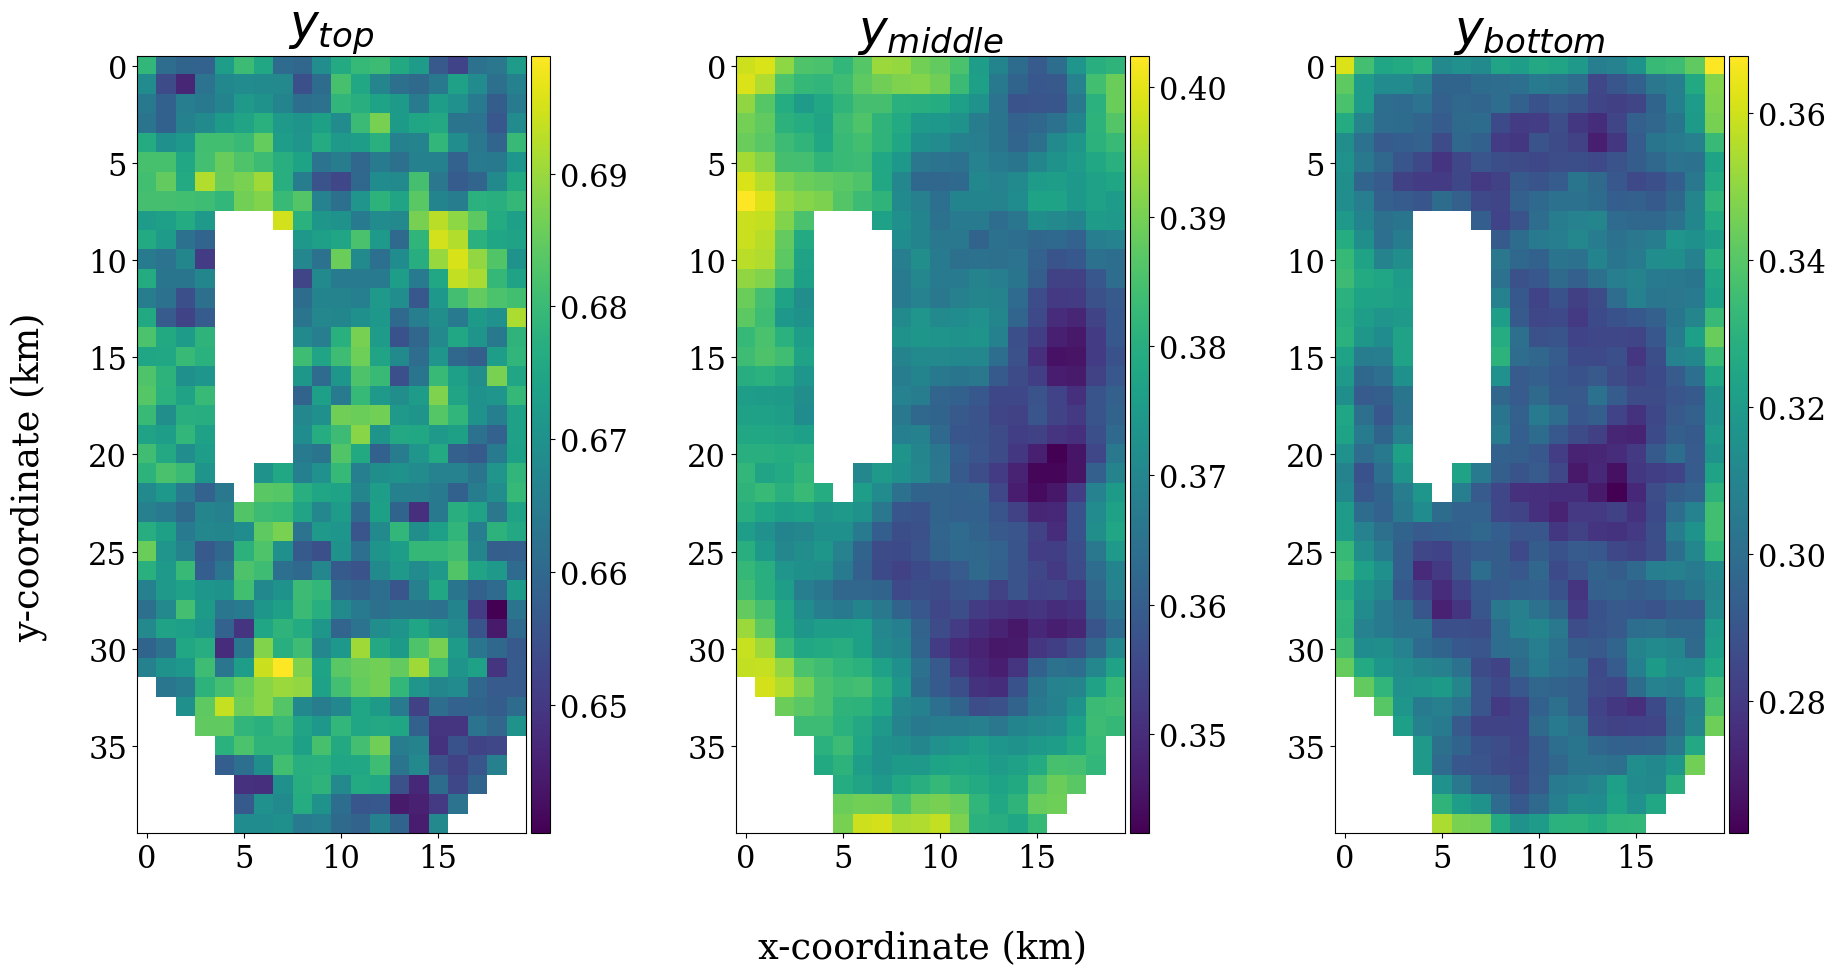

In [39]:
import matplotlib.ticker as ticker
import matplotlib.ticker as tkr
Ntest = -1

f, (ax7, ax8,ax9) = plt.subplots(1, 3,figsize=(19,10))
conI95_1=ax7.imshow(mesh_recon_y(y_reconAll_std[:706]))
divider = make_axes_locatable(ax7)
cax = divider.append_axes("right", size="5%", pad=0.05)
f.colorbar(conI95_1, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax7.set_title('$y_{top}$',fontsize=35)

conI95_2=ax8.imshow(mesh_recon_y(y_reconAll_std[706:1412]))
divider = make_axes_locatable(ax8)
cax = divider.append_axes("right", size="5%", pad=0.05)
f.colorbar(conI95_2, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax8.set_title('$y_{middle}$',fontsize=35)

conI95_3=ax9.imshow(mesh_recon_y(y_reconAll_std[-706:]))
divider = make_axes_locatable(ax9)
cax = divider.append_axes("right", size="5%", pad=0.05)
f.colorbar(conI95_3, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax9.set_title('$y_{bottom}$',fontsize=35)

f.supxlabel('x-coordinate (km)')
f.supylabel('y-coordinate (km)')

f.tight_layout()
# output_dir = "New_results"
# output_path = os.path.join(output_dir, "UQ.png")
# plt.savefig(output_path, dpi=600, bbox_inches='tight')
plt.show()

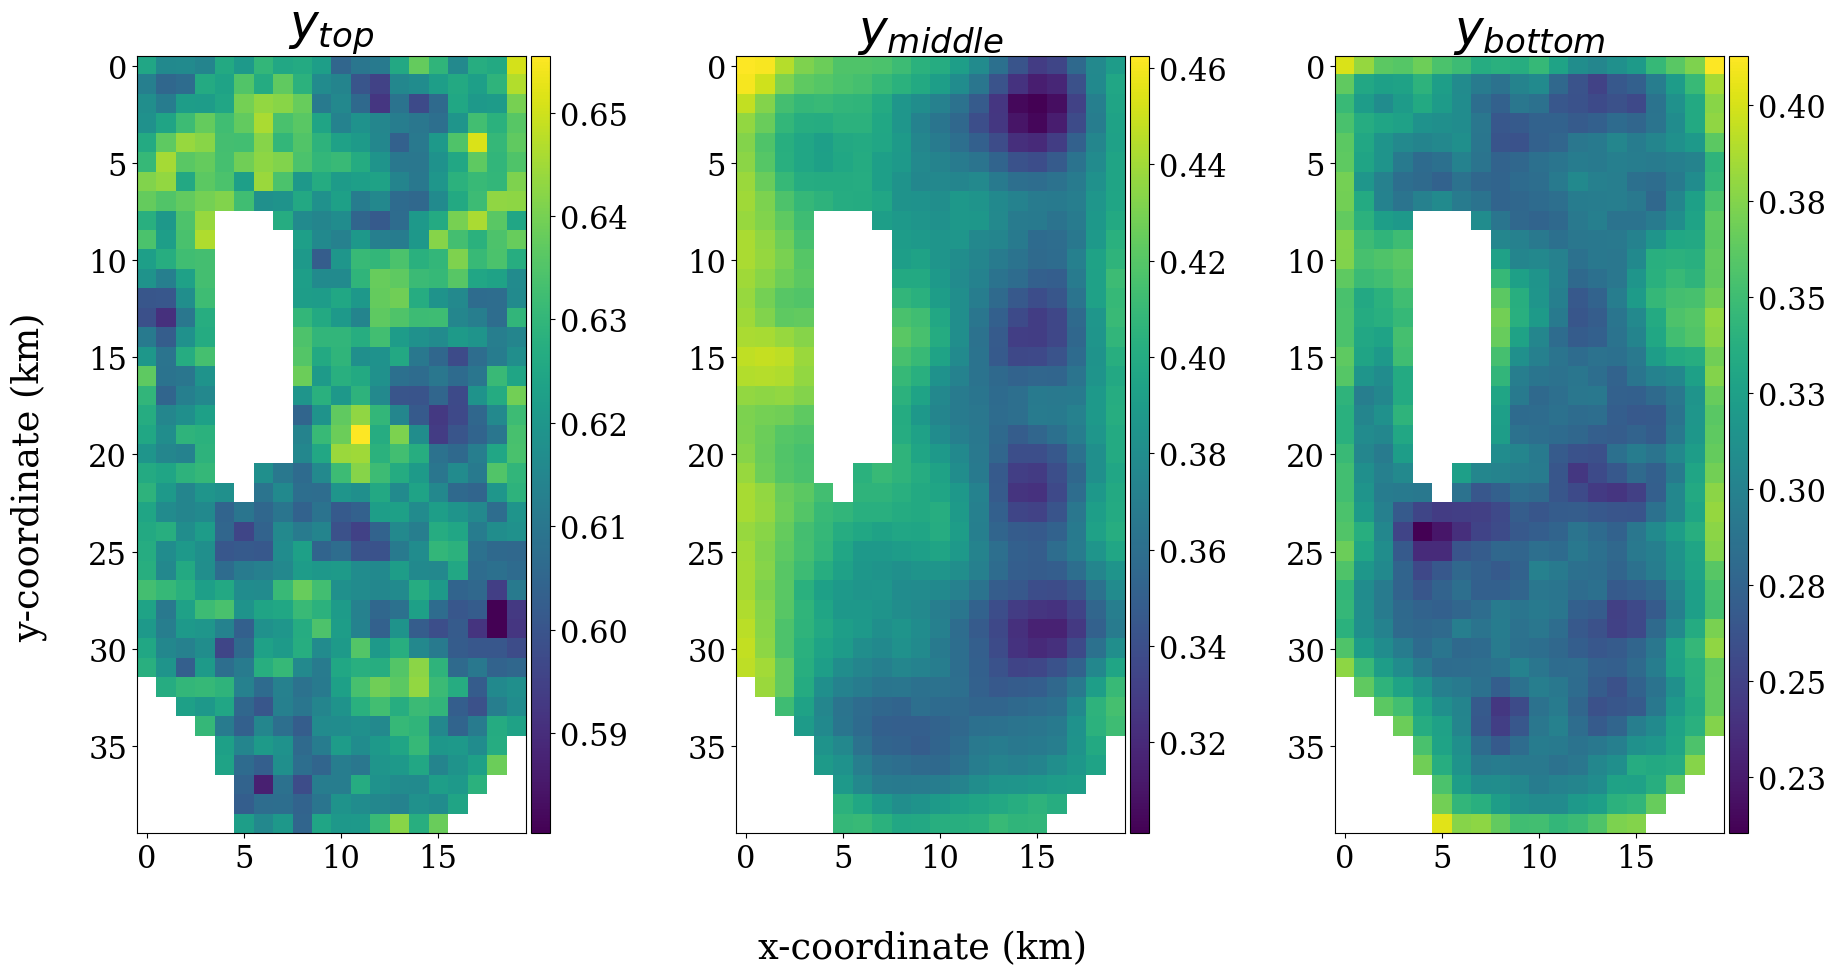

In [116]:
import matplotlib.ticker as ticker
import matplotlib.ticker as tkr
Ntest = -1

f, (ax7, ax8,ax9) = plt.subplots(1, 3,figsize=(19,10))
conI95_1=ax7.imshow(mesh_recon_y(y_reconAll_std[:706]))
divider = make_axes_locatable(ax7)
cax = divider.append_axes("right", size="5%", pad=0.05)
f.colorbar(conI95_1, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax7.set_title('$y_{top}$',fontsize=35)

conI95_2=ax8.imshow(mesh_recon_y(y_reconAll_std[706:1412]))
divider = make_axes_locatable(ax8)
cax = divider.append_axes("right", size="5%", pad=0.05)
f.colorbar(conI95_2, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax8.set_title('$y_{middle}$',fontsize=35)

conI95_3=ax9.imshow(mesh_recon_y(y_reconAll_std[-706:]))
divider = make_axes_locatable(ax9)
cax = divider.append_axes("right", size="5%", pad=0.05)
f.colorbar(conI95_3, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax9.set_title('$y_{bottom}$',fontsize=35)

f.supxlabel('x-coordinate (km)')
f.supylabel('y-coordinate (km)')

f.tight_layout()
# output_dir = "New_results"
# output_path = os.path.join(output_dir, "UQ.png")
# plt.savefig(output_path, dpi=600, bbox_inches='tight')
plt.show()

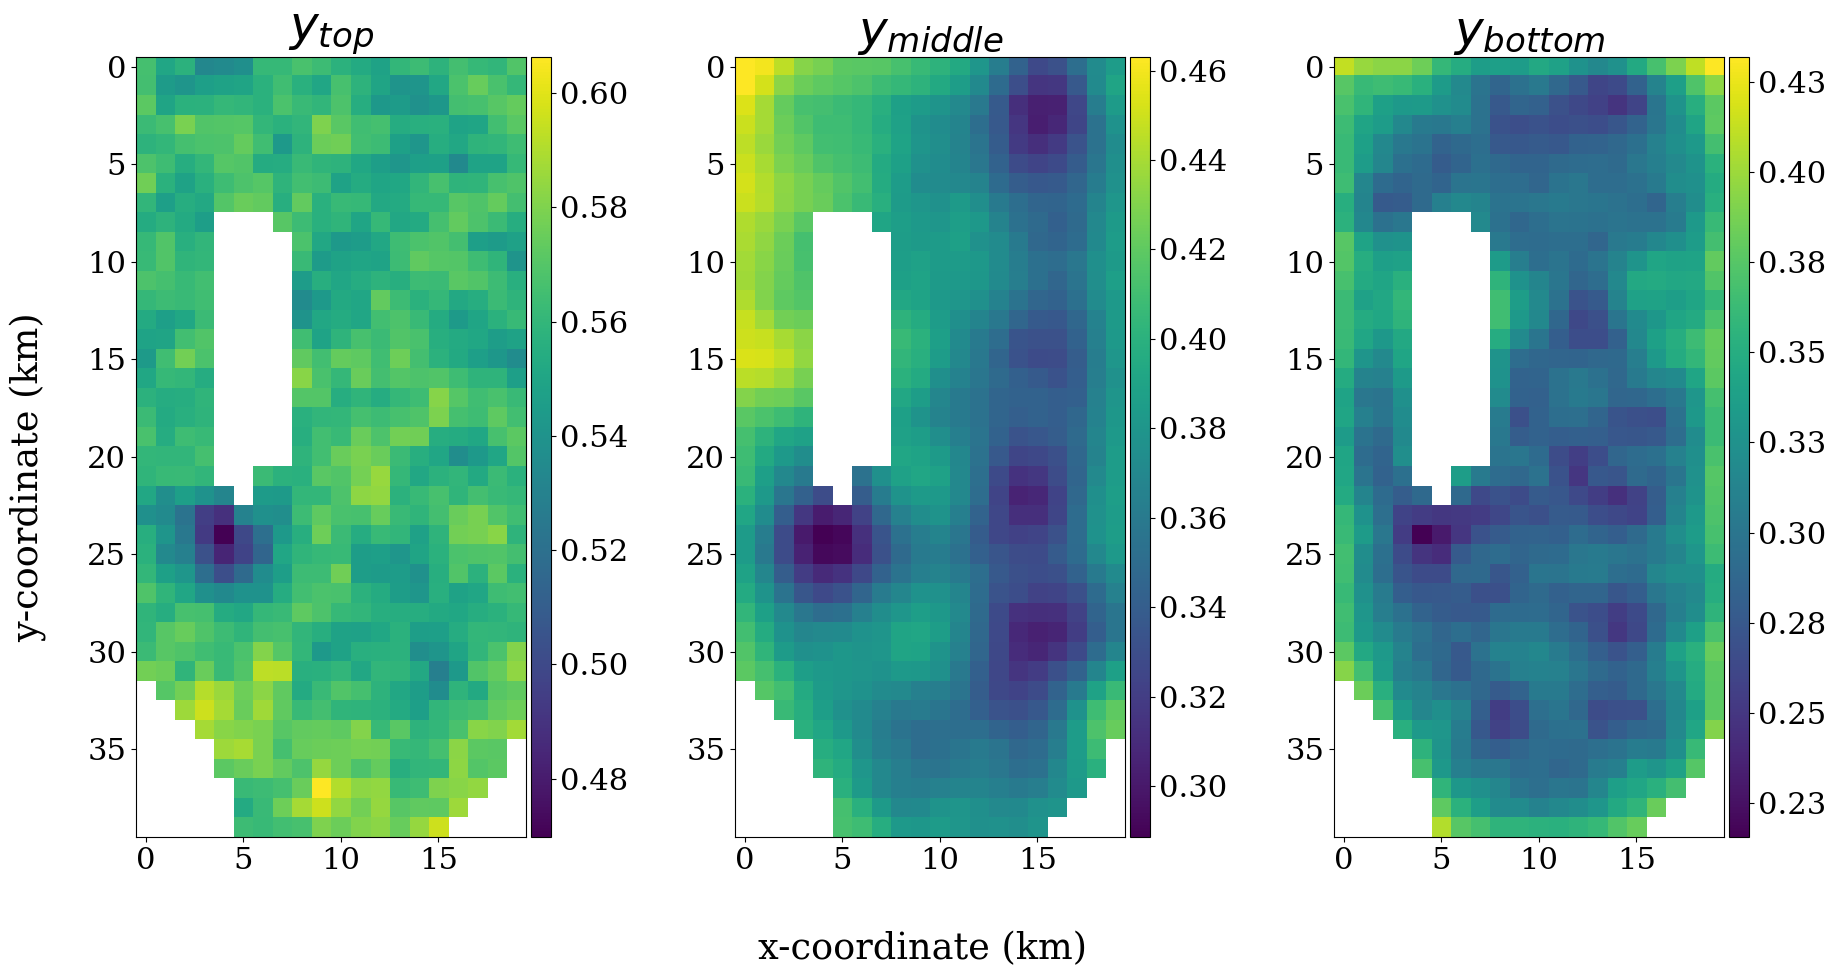

In [88]:
import matplotlib.ticker as ticker
Ntest = -1

f, (ax7, ax8,ax9) = plt.subplots(1, 3,figsize=(19,10))
conI95_1=ax7.imshow(mesh_recon_y(y_reconAll_std[:706]))
divider = make_axes_locatable(ax7)
cax = divider.append_axes("right", size="5%", pad=0.05)
f.colorbar(conI95_1, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax7.set_title('$y_{top}$',fontsize=35)

conI95_2=ax8.imshow(mesh_recon_y(y_reconAll_std[706:1412]))
divider = make_axes_locatable(ax8)
cax = divider.append_axes("right", size="5%", pad=0.05)
f.colorbar(conI95_2, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax8.set_title('$y_{middle}$',fontsize=35)

conI95_3=ax9.imshow(mesh_recon_y(y_reconAll_std[-706:]))
divider = make_axes_locatable(ax9)
cax = divider.append_axes("right", size="5%", pad=0.05)
f.colorbar(conI95_3, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax9.set_title('$y_{bottom}$',fontsize=35)

f.supxlabel('x-coordinate (km)')
f.supylabel('y-coordinate (km)')

f.tight_layout()
plt.show()

In [17]:
Ntest=-1
NY_term1=344
y_recon1 = meany1 + PsiY1[:,:NY_term1] @ layer1_mean[Ntest,:NY_term1]
print(y_recon1.shape)

NY_term2=61
y_recon2 = meany2 + PsiY2[:,:NY_term2] @ layer2_mean[Ntest,:NY_term2]
print(y_recon2.shape)

NY_term3=226
y_recon3 = meany3 + PsiY3[:,:NY_term3] @ layer3_mean[Ntest,:NY_term3]
print(y_recon3.shape)

# print(rl2e_y(np.mean(recon,axis=0),y_ref))
y_reconAll = np.hstack([y_recon1[:706],y_recon2[:706],y_recon3[:706]])
print(y_reconAll.shape)


(707,)
(707,)
(707,)
(2118,)


In [18]:
y_const = np.hstack([y_recon1[-1],y_recon2[-1],y_recon3[-1]])
y_const
# [-2.21559066 -2.35111167 -2.40002645]
# [-1.67088734 -2.06605317 -3.15631026]

array([-2.19462064, -2.30157211, -2.4400839 ])

In [36]:
## 61 parameters
y_ref = y[:,(4800+100):(4800+201)][:2118,Ntest]
overall_error = rl2e_y(y_reconAll,y_ref)
print('The overall L2 error:',overall_error)
top_error = rl2e_y(y_reconAll[:706],y_ref[:706])
mid_error = rl2e_y(y_reconAll[706:706*2],y_ref[706:706*2])
bot_error = rl2e_y(y_reconAll[-706:],y_ref[-706:])
print('The top L2 error:',top_error)
print('The middle L2 error:',mid_error)
print('The bottom L2 error:',bot_error)

The overall L2 error: 0.2070211878346841
The top L2 error: 0.7312921384045161
The middle L2 error: 0.2785676148907423
The bottom L2 error: 0.08872312026798199


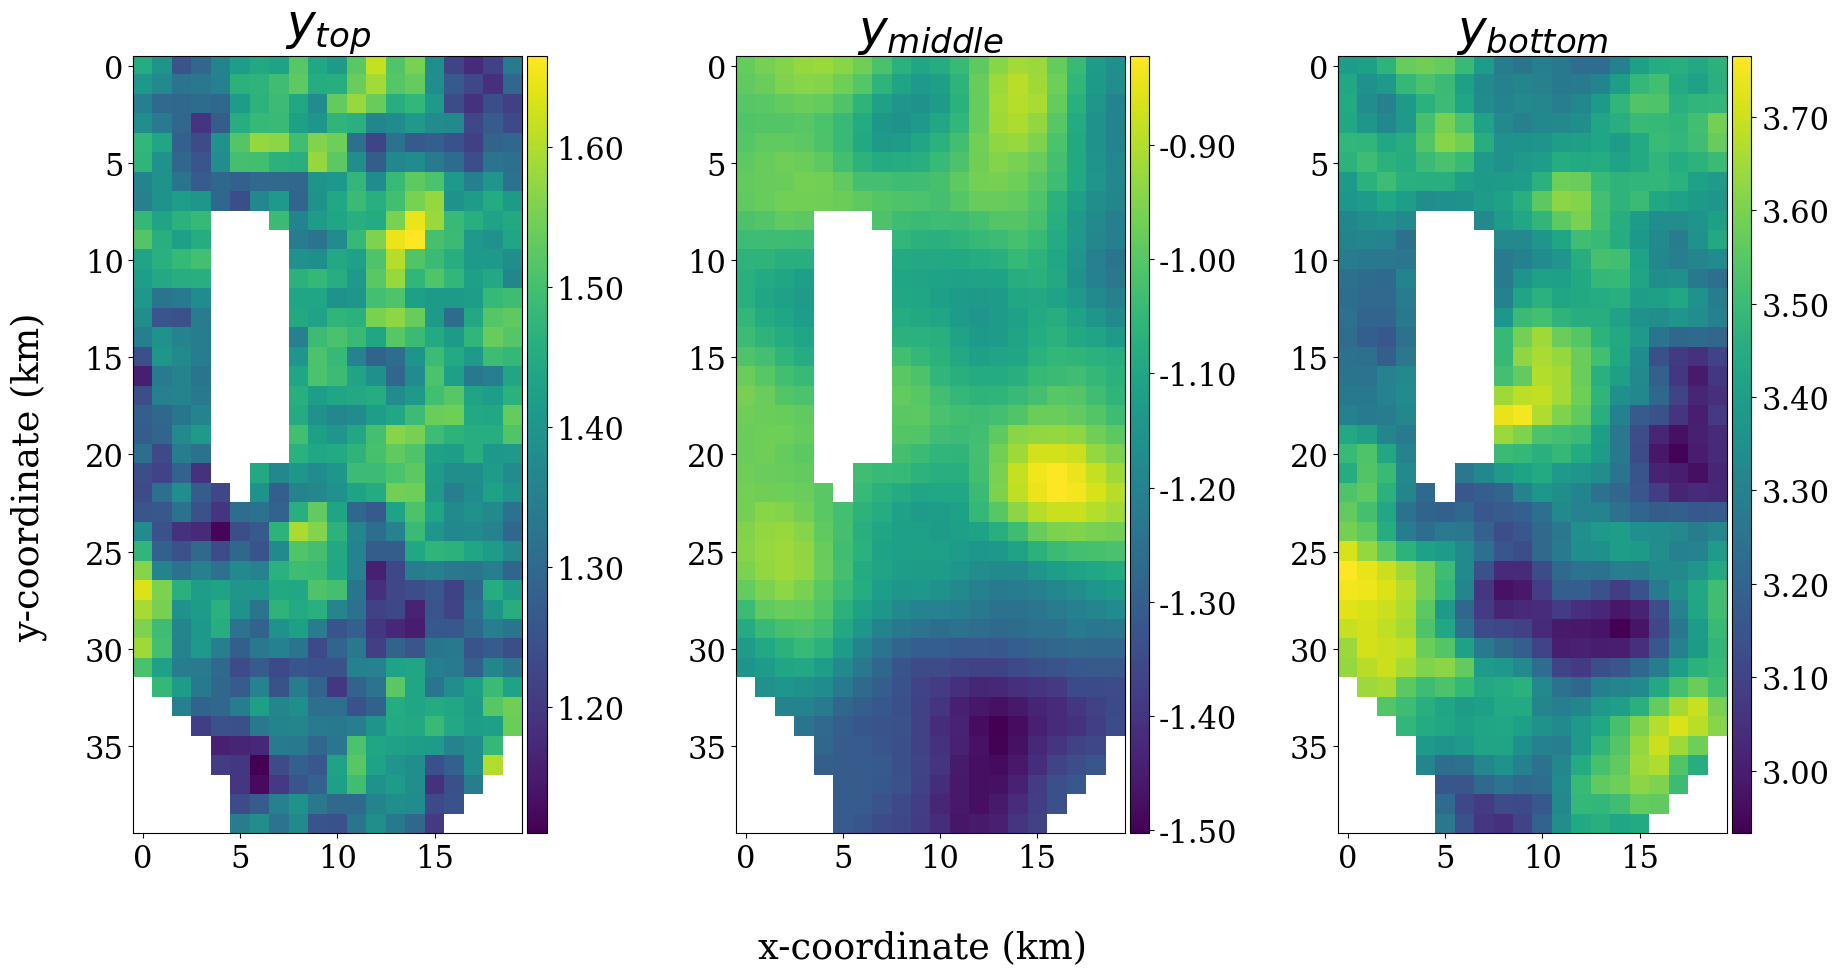

In [19]:
import matplotlib.ticker as tkr
import matplotlib
font = {'family' : 'serif',
        'weight' : 'normal',
        'size'   : 22}

matplotlib.rc('font', **font)
dx = 0.
dy = 0.
extent = [0-dx, 5+dx, 0-dy, 10+dy]

f, (ax1, ax2, ax3) = plt.subplots(1, 3,figsize=(19,10))
layer1=ax1.imshow(mesh_recon_y(y_recon1[:706]))
divider = make_axes_locatable(ax1)
cax = divider.append_axes("right", size="5%", pad=0.05)
f.colorbar(layer1, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax1.set_title('$y_{top}$', fontweight ="bold",fontsize=35)

layer2=ax2.imshow(mesh_recon_y(y_recon2[:706]))
divider = make_axes_locatable(ax2)
cax = divider.append_axes("right", size="5%", pad=0.05)
f.colorbar(layer2, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax2.set_title('$y_{middle}$', fontweight ="bold",fontsize=35)

layer3=ax3.imshow(mesh_recon_y(y_recon3[:706]))
divider = make_axes_locatable(ax3)
cax = divider.append_axes("right", size="5%", pad=0.05)
f.colorbar(layer3, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax3.set_title('$y_{bottom}$', fontweight ="bold",fontsize=35)

f.supxlabel('x-coordinate (km)')
f.supylabel('y-coordinate (km)')

f.tight_layout()
# output_dir = "New_results"
# output_path = os.path.join(output_dir, "Postmean.png")
# plt.savefig(output_path, dpi=600, bbox_inches='tight')
plt.show()

In [20]:
y_ref = y[:,(4800+100):(4800+201)][:2118,Ntest]
overall_error = rl2e_y(y_reconAll,y_ref)
print('The overall L2 error:',overall_error)
top_error = rl2e_y(y_reconAll[:706],y_ref[:706])
mid_error = rl2e_y(y_reconAll[706:706*2],y_ref[706:706*2])
bot_error = rl2e_y(y_reconAll[-706:],y_ref[-706:])
print('The top L2 error:',top_error)
print('The middle L2 error:',mid_error)
print('The bottom L2 error:',bot_error)

The overall L2 error: 0.2170373293574019
The top L2 error: 0.8501941974045509
The middle L2 error: 0.2317584163088579
The bottom L2 error: 0.06996837568856075


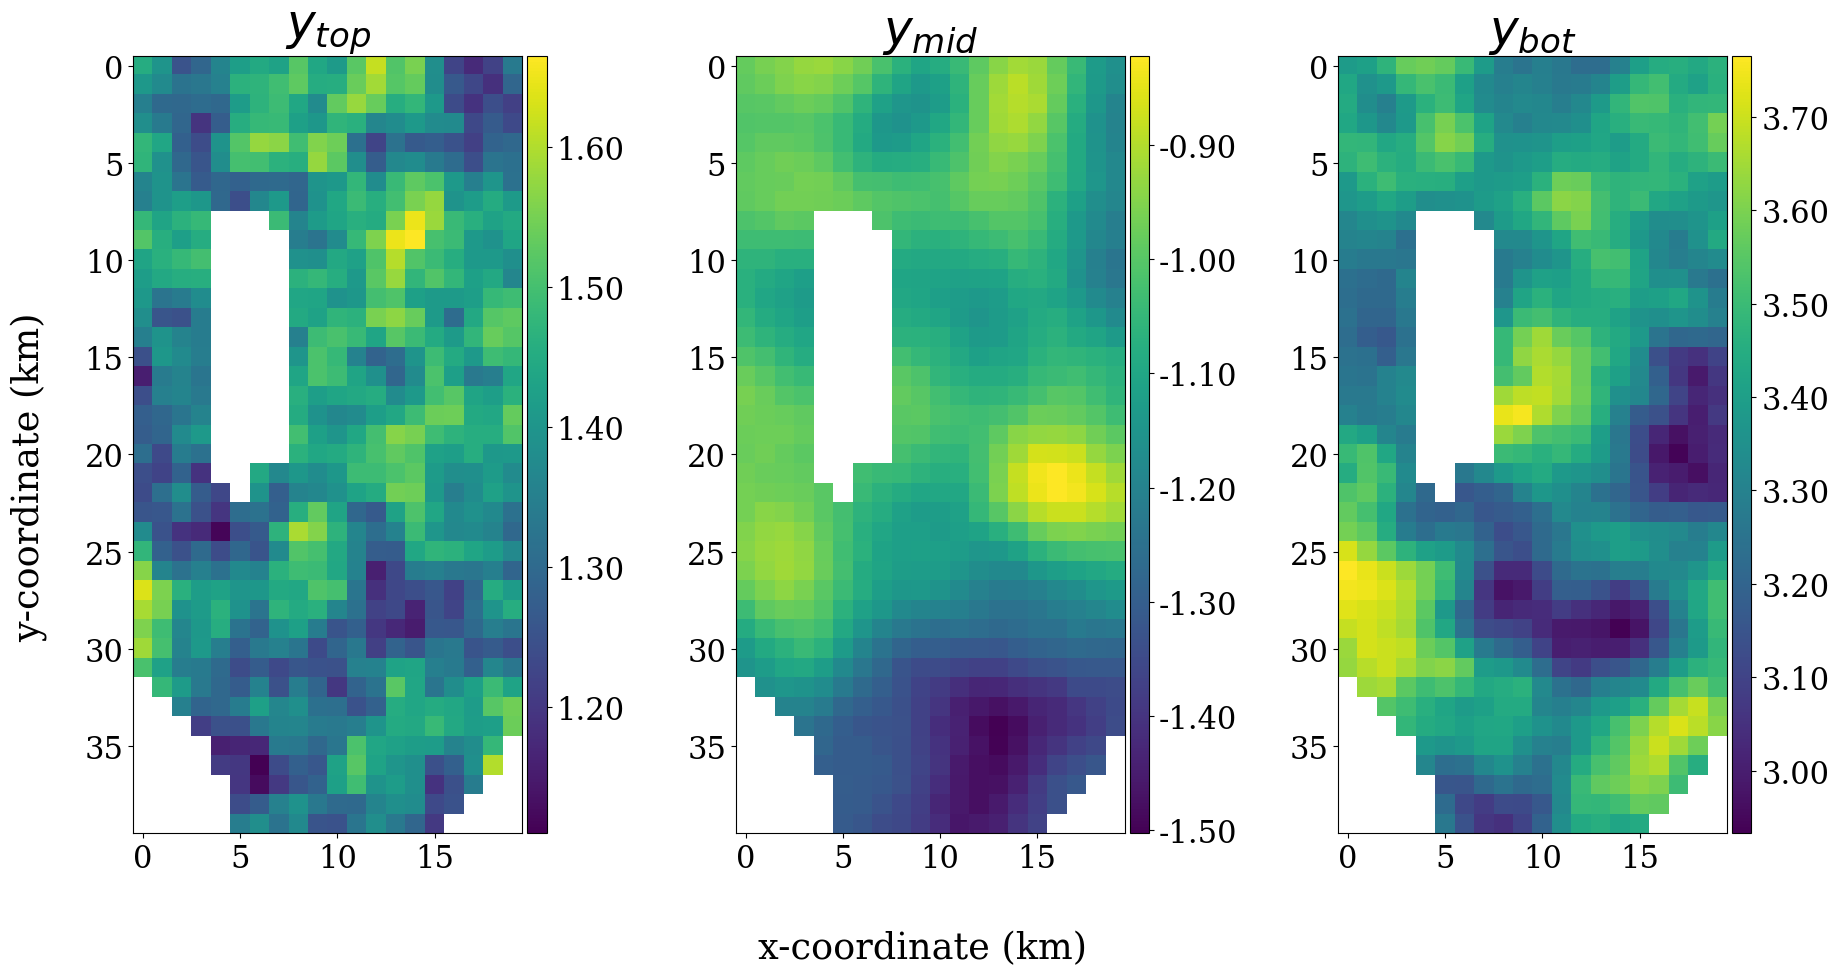

In [121]:
import matplotlib.ticker as tkr
import matplotlib
font = {'family' : 'serif',
        'weight' : 'normal',
        'size'   : 22}

matplotlib.rc('font', **font)
dx = 0.0
dy = 0.0
extent = [0-dx, 5+dx, 0-dy, 10+dy]

f, (ax1, ax2, ax3) = plt.subplots(1, 3,figsize=(19,10))
layer1=ax1.imshow(mesh_recon_y(y_recon1[:706]))
divider = make_axes_locatable(ax1)
cax = divider.append_axes("right", size="5%", pad=0.05)
f.colorbar(layer1, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax1.set_title('$y_{top}$', fontweight ="bold",fontsize=35)

layer2=ax2.imshow(mesh_recon_y(y_recon2[:706]))
divider = make_axes_locatable(ax2)
cax = divider.append_axes("right", size="5%", pad=0.05)
f.colorbar(layer2, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax2.set_title('$y_{mid}$', fontweight ="bold",fontsize=35)

layer3=ax3.imshow(mesh_recon_y(y_recon3[:706]))
divider = make_axes_locatable(ax3)
cax = divider.append_axes("right", size="5%", pad=0.05)
f.colorbar(layer3, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax3.set_title('$y_{bot}$', fontweight ="bold",fontsize=35)

f.supxlabel('x-coordinate (km)')
f.supylabel('y-coordinate (km)')

f.tight_layout()
plt.show()

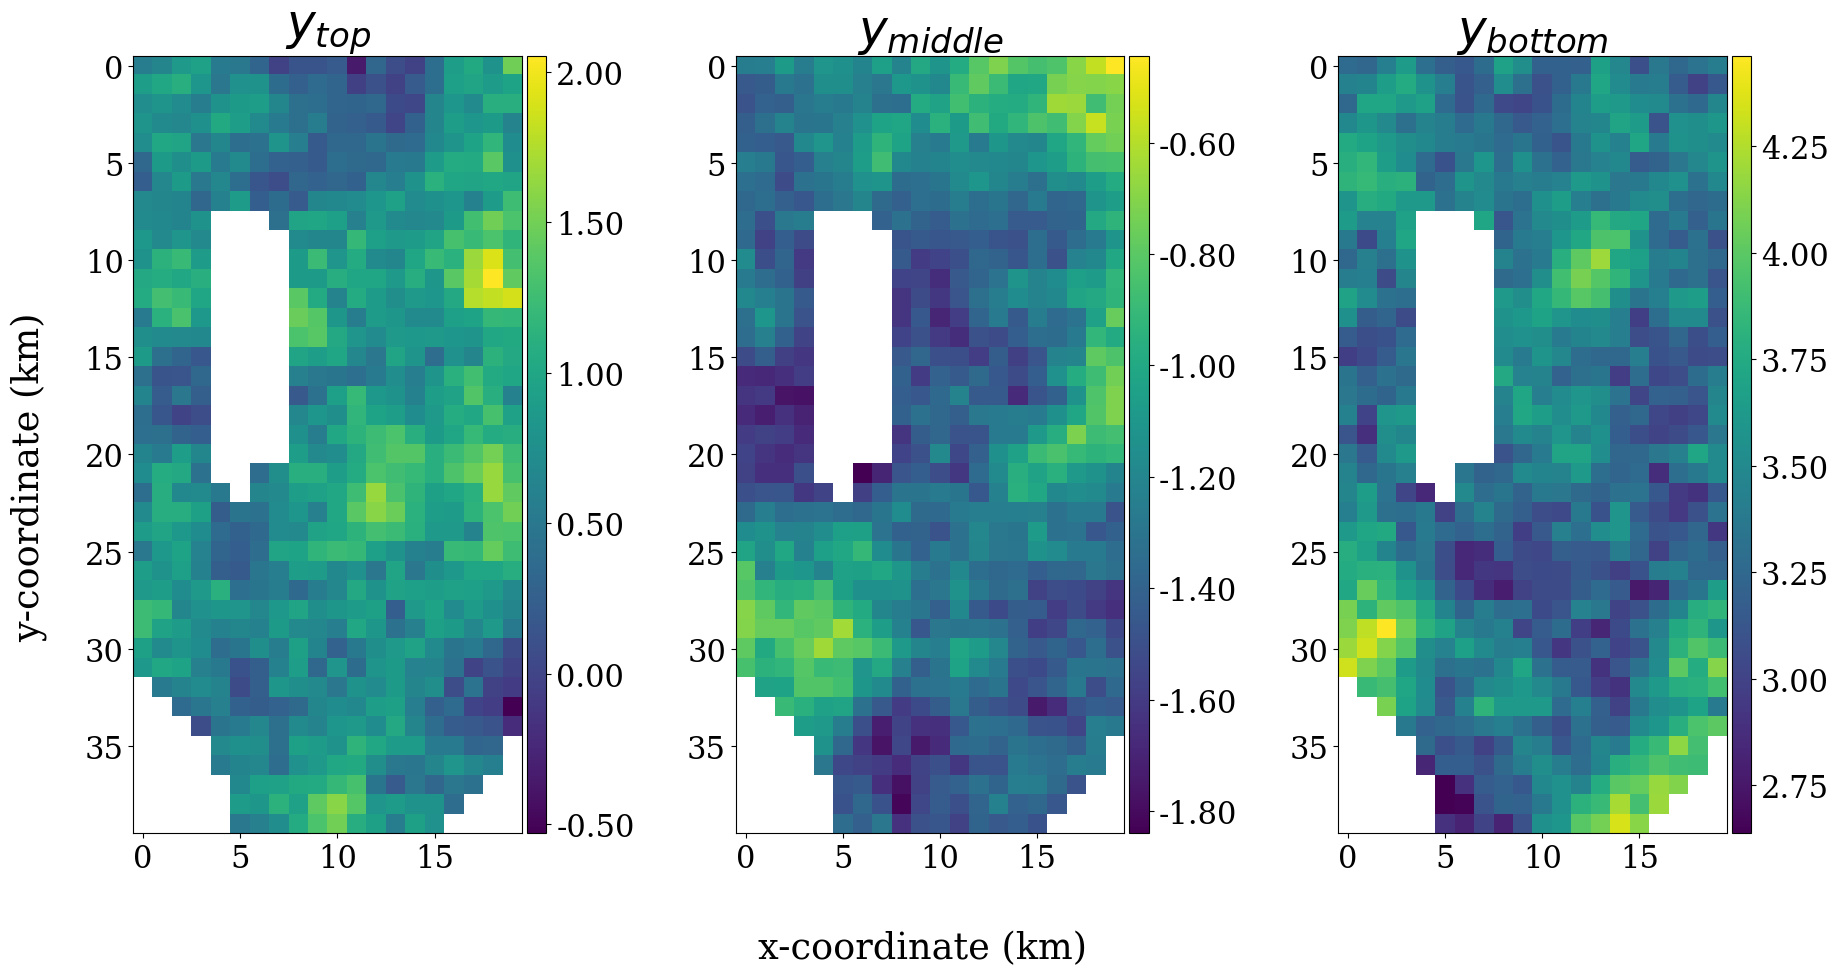

In [21]:
Ntest=-1
f, (ax1, ax2, ax3) = plt.subplots(1, 3,figsize=(19,10))
layer1=ax1.imshow(mesh_recon_y(y_ref[:706]))
divider = make_axes_locatable(ax1)
cax = divider.append_axes("right", size="5%", pad=0.05)
f.colorbar(layer1, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax1.set_title('$y_{top}$', fontweight ="bold",fontsize=35)

layer2=ax2.imshow(mesh_recon_y(y_ref[706:1412]))
divider = make_axes_locatable(ax2)
cax = divider.append_axes("right", size="5%", pad=0.05)
f.colorbar(layer2, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax2.set_title('$y_{middle}$', fontweight ="bold",fontsize=35)

layer3=ax3.imshow(mesh_recon_y(y_ref[-706:]))
divider = make_axes_locatable(ax3)
cax = divider.append_axes("right", size="5%", pad=0.05)
f.colorbar(layer3, cax=cax,format=tkr.FormatStrFormatter('%.2f'))
ax3.set_title('$y_{bottom}$', fontweight ="bold",fontsize=35)

f.supxlabel('x-coordinate (km)')
f.supylabel('y-coordinate (km)')

f.tight_layout()
plt.show()

In [22]:
# compute LPP
def lpp_ens(pred_mean,pred_std,alpha): # ens is predicted, alpha is true
    mu = pred_mean
    sigma = pred_std
    return -np.sum((mu-alpha)**2/(2*(sigma)**2) + np.log(2*np.pi*sigma**2)/2)

LPP=lpp_ens(y_reconAll_mean,y_reconAll_std,y_ref)
print('The overall LPP:',LPP)


The overall LPP: -998.3585901003291


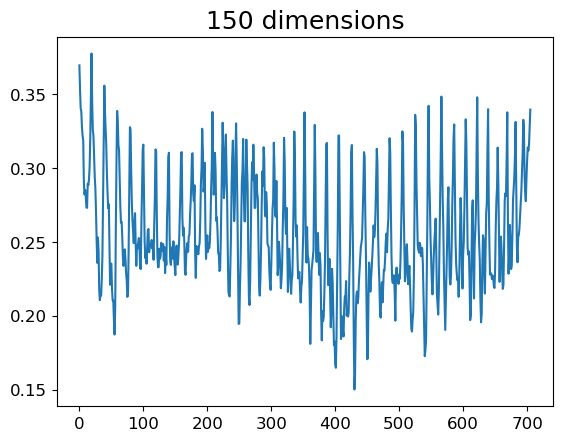

In [104]:
plt.plot(np.std(recon,axis=0))
# plt.ylim([0.02,0.055])
plt.yticks(fontsize=12)
plt.xticks(fontsize=12)
plt.title('150 dimensions', fontsize=18)
plt.show()

## Reconstruction error (last realization)

In [19]:
# Plot the reconstruction error as a function of number of terms
# NT=500
# true=y[:,(NT+100):(NT+201)]
y_ref = layer1[:,-1]
err_y_recon = []
NY_term=50
for i in range(1,NY_term):
    err_y_recon.append(rl2e_y(meany1 + PsiY1[:,:i] @ xiY_ref[:i],y_ref))
#     err_y_recon.append(rl2e_y(meany + PsiY[:,:i] @ pos_mean13D[-1,:i],y_ref))
#     err_y_recon.append(rl2e_y(meany + PsiY[:,:i] @ post_mean5000[0,:i],y_ref))
#     err_y_recon.append(rl2e_y(meany + PsiY[:,:i] @ post_mean[-1,:i],y_ref))
# err_h_recon = []
# for i in range(1,Nh_term):
#     err_h_recon.append(rl2e_y(meanh + Psih[:,:i] @ etah_ref[:i],h_ref))

In [20]:
np.min(err_y_recon)

0.23121812534954383

Text(0.5, 0, 'Dimension of y')

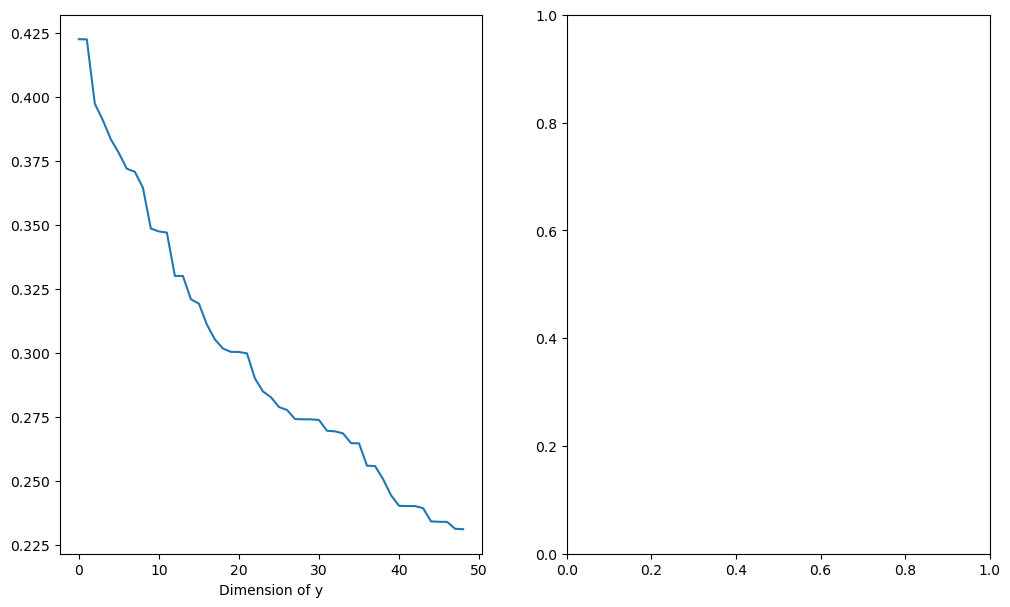

In [21]:
fig, ax  = plt.subplots(1,2,figsize=(12,7))
ax[0].plot(err_y_recon)
ax[0].set_xlabel('Dimension of y')
# ax[1].plot(err_h_recon)
# ax[1].set_xlabel('Dimension of h')

## Reconstruction visualization (last realization)

In [41]:
# y_recon = meany + PsiY[:,:NY_term] @ xiY_ref[:NY_term]
# y_recon = meany + PsiY[:,:50] @ post_mean[-1,:50]
# y_recon = meany + PsiY[:,:NY_term] @ post_mean_HY[-1,:NY_term]
y_recon = meany + PsiY[:,:NY_term] @ pos_mean13D[-1,:NY_term]
h_recon = meanh + Psih[:,:Nh_term] @ etah_ref[:Nh_term]

y_recon_mesh = mesh_recon_y(y_recon)
h_recon_mesh = mesh_recon_h(h_recon)

In [42]:
y_recon.shape

(706,)

In [43]:
print(rl2e_y(y_recon,y_ref))

0.15278325258975345


In [55]:
ymin = min(np.min(y_recon),np.min(y_ref))
ymax = max(np.max(y_recon),np.max(y_ref))
fig, ax  = plt.subplots(1,3,figsize=(14,7))
ref_y = ax[0].imshow(y_ref_mesh, vmin=ymin, vmax=ymax)
ax[0].set_xlabel('refernce y')
recon_y = ax[1].imshow(y_recon_mesh, vmin=ymin, vmax=ymax)
ax[1].set_xlabel('reconstructed y')
error_y = ax[2].imshow(y_ref_mesh-y_recon_mesh)
ax[2].set_xlabel('reconstructed error')

divider0 = make_axes_locatable(ax[0])
cax0 = divider0.append_axes("right", size="5%", pad=0.05)
fig.colorbar(ref_y, cax=cax0)

divider1 = make_axes_locatable(ax[1])
cax1 = divider1.append_axes("right", size="5%", pad=0.05)
fig.colorbar(recon_y, cax=cax1)

divider2 = make_axes_locatable(ax[2])
cax2 = divider2.append_axes("right", size="5%", pad=0.05)
fig.colorbar(error_y, cax=cax2)

NameError: name 'y_recon' is not defined

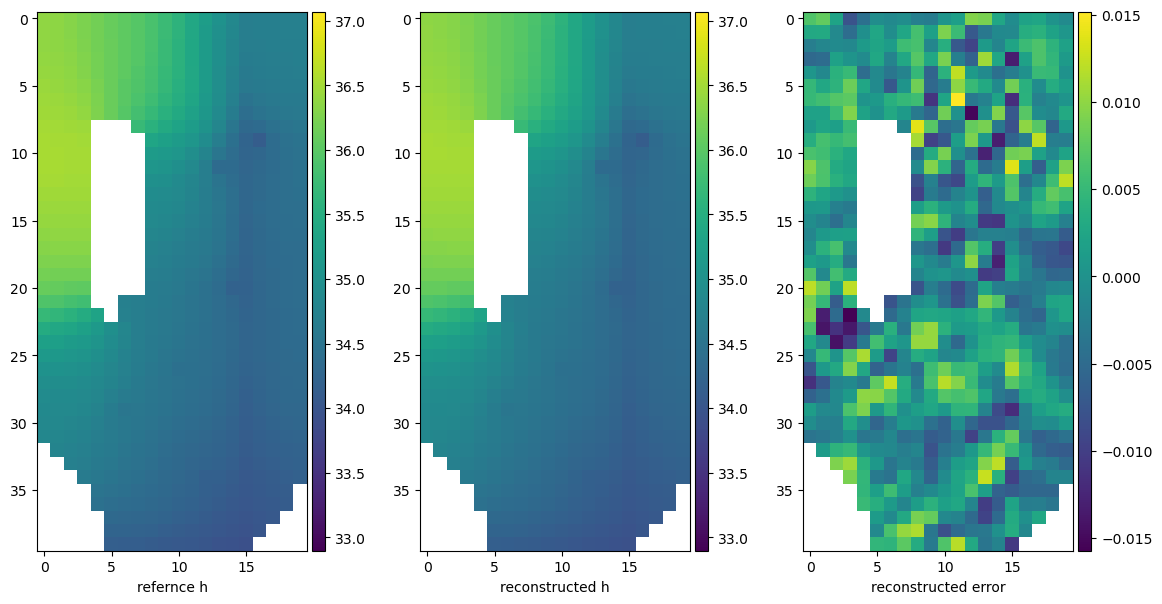

In [60]:
hmin = min(np.min(h_recon),np.min(h_ref))
hmax = max(np.max(h_recon),np.max(h_ref))
fig, ax  = plt.subplots(1,3,figsize=(14,7))
ref_h = ax[0].imshow(h_ref_mesh[0], vmin=hmin, vmax=hmax)
ax[0].set_xlabel('refernce h')
recon_h = ax[1].imshow(h_recon_mesh[0], vmin=hmin, vmax=hmax)
ax[1].set_xlabel('reconstructed h')
error_h = ax[2].imshow(h_ref_mesh[0]-h_recon_mesh[0])
ax[2].set_xlabel('reconstructed error')

divider0 = make_axes_locatable(ax[0])
cax0 = divider0.append_axes("right", size="5%", pad=0.05)
fig.colorbar(ref_h, cax=cax0)

divider1 = make_axes_locatable(ax[1])
cax1 = divider1.append_axes("right", size="5%", pad=0.05)
fig.colorbar(recon_h, cax=cax1)

divider2 = make_axes_locatable(ax[2])
cax2 = divider2.append_axes("right", size="5%", pad=0.05)
fig.colorbar(error_h, cax=cax2)